OpenCV Version: 5.0.0
Grayscale Image Shape: (1240, 1754)
Grayscale Image Data Type: uint8
Colour Image Shape: (480, 512, 3)
Colour Image Data Type: uint8


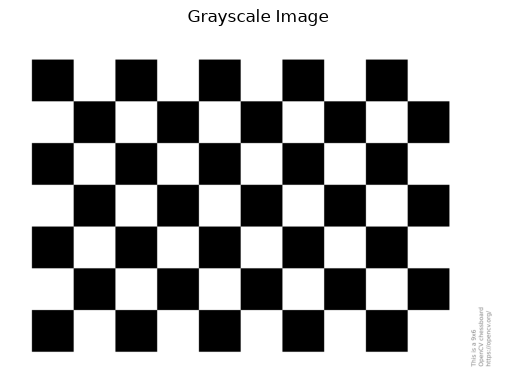

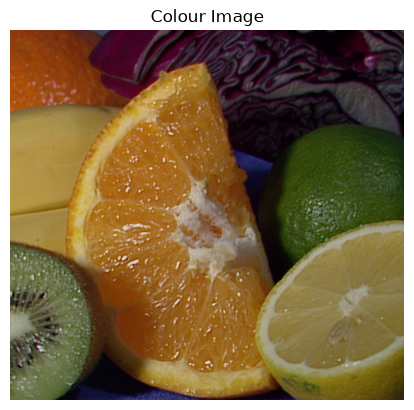

In [13]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os


print("OpenCV Version:", cv2.__version__)

IMAGE_PATH = "data/images/"

gray_img = cv2.imread(
    IMAGE_PATH + "chessboard.png",
    cv2.IMREAD_GRAYSCALE
)

color_img = cv2.imread(
    IMAGE_PATH + "fruits.jpg"
)

print("Grayscale Image Shape:", gray_img.shape)
print("Grayscale Image Data Type:", gray_img.dtype)

print("Colour Image Shape:", color_img.shape)
print("Colour Image Data Type:", color_img.dtype)

def show(img, title):
    if len(img.shape) == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.imshow(img, cmap="gray")
    plt.title(title)
    plt.axis("off")
    plt.show()

show(gray_img, "Grayscale Image")
show(color_img, "Colour Image")

Threshold Value: 127.0


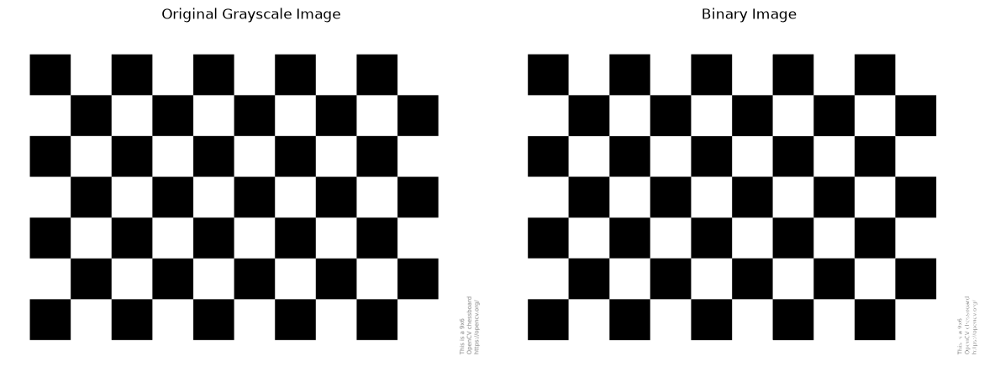

In [14]:
threshold_value, binary_img = cv2.threshold(
    gray_img,
    127,
    255,
    cv2.THRESH_BINARY
)

print("Threshold Value:", threshold_value)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray_img, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary_img, cmap="gray")
plt.title("Binary Image")
plt.axis("off")

plt.tight_layout()
plt.show()

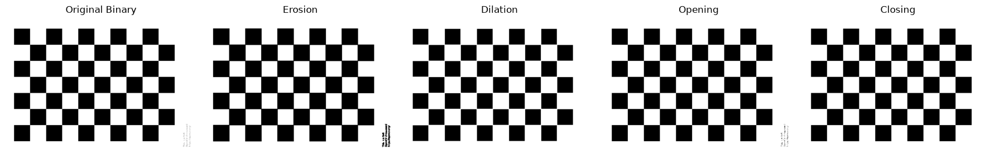

In [15]:
kernel = np.ones((5, 5), np.uint8)

erosion = cv2.erode(
    binary_img,
    kernel,
    iterations=1
)

dilation = cv2.dilate(
    binary_img,
    kernel,
    iterations=1
)

opening = cv2.morphologyEx(
    binary_img,
    cv2.MORPH_OPEN,
    kernel
)

closing = cv2.morphologyEx(
    binary_img,
    cv2.MORPH_CLOSE,
    kernel
)

images = [
    binary_img,
    erosion,
    dilation,
    opening,
    closing
]

titles = [
    "Original Binary",
    "Erosion",
    "Dilation",
    "Opening",
    "Closing"
]

plt.figure(figsize=(18, 5))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

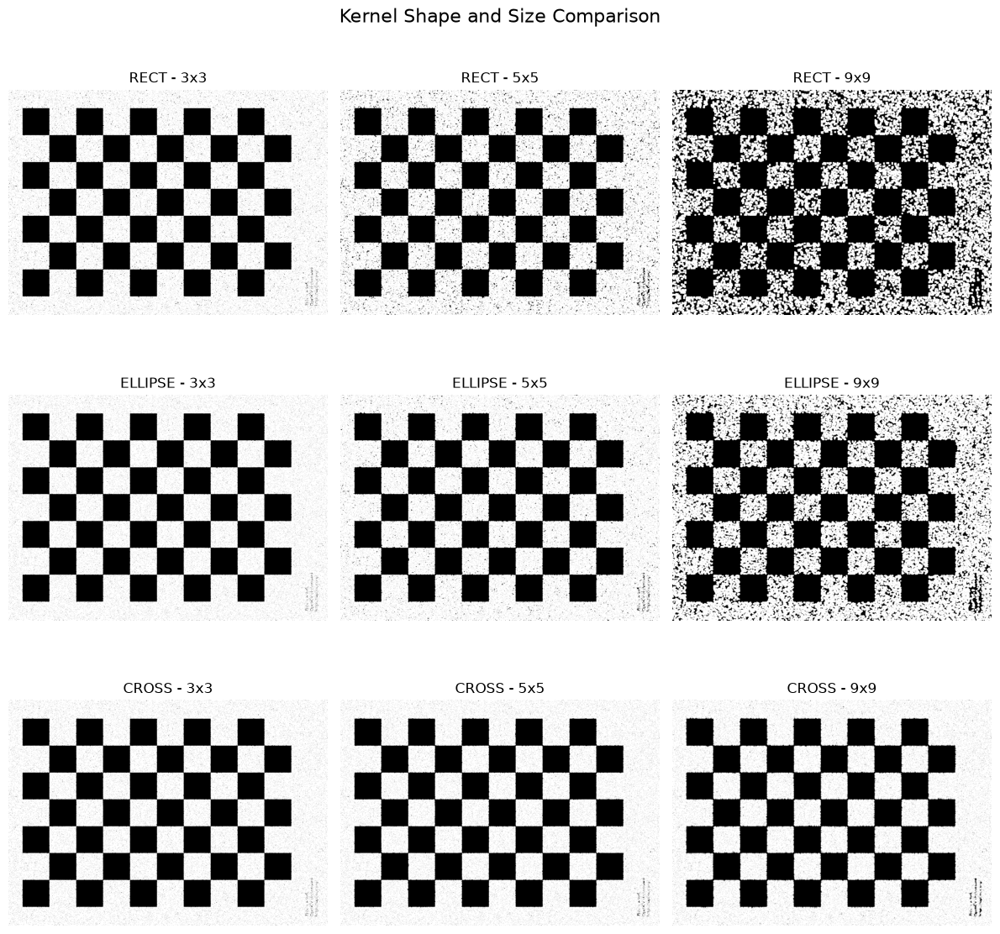

In [16]:
np.random.seed(42)

noisy_img = binary_img.copy()


noise = np.random.choice(
    [0, 255],
    size=binary_img.shape,
    p=[0.5, 0.5]
)

noise_mask = np.random.random(binary_img.shape) < 0.05

noisy_img[noise_mask] = noise[noise_mask]

kernel_shapes = {
    "RECT": cv2.MORPH_RECT,
    "ELLIPSE": cv2.MORPH_ELLIPSE,
    "CROSS": cv2.MORPH_CROSS
}


kernel_sizes = [3, 5, 9]

plt.figure(figsize=(12, 12))

plot_number = 1

for shape_name, shape_type in kernel_shapes.items():

    for size in kernel_sizes:

        kernel = cv2.getStructuringElement(
            shape_type,
            (size, size)
        )

        # Apply Morphological Opening
        result = cv2.morphologyEx(
            noisy_img,
            cv2.MORPH_OPEN,
            kernel
        )

        plt.subplot(3, 3, plot_number)
        plt.imshow(result, cmap="gray")
        plt.title(f"{shape_name} - {size}x{size}")
        plt.axis("off")

        plot_number += 1

plt.suptitle(
    "Kernel Shape and Size Comparison",
    fontsize=16
)

plt.tight_layout()
plt.show()

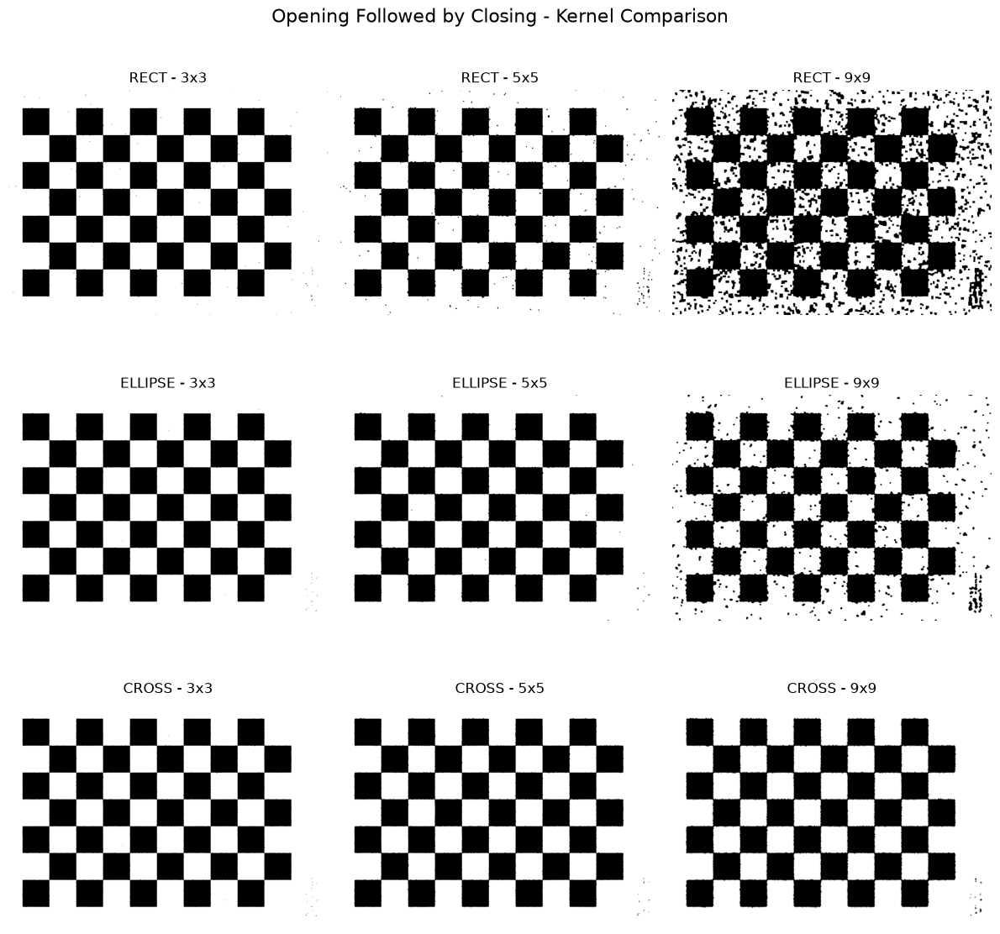

In [17]:
fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for i, (shape_name, shape_type) in enumerate(kernel_shapes.items()):

    for j, size in enumerate(kernel_sizes):

        kernel = cv2.getStructuringElement(
            shape_type,
            (size, size)
        )

        opened = cv2.morphologyEx(
            noisy_img,
            cv2.MORPH_OPEN,
            kernel
        )

        closed = cv2.morphologyEx(
            opened,
            cv2.MORPH_CLOSE,
            kernel
        )

        axes[i, j].imshow(closed, cmap="gray")
        axes[i, j].set_title(
            f"{shape_name} - {size}x{size}"
        )
        axes[i, j].axis("off")

plt.suptitle(
    "Opening Followed by Closing - Kernel Comparison",
    fontsize=16
)

plt.tight_layout()
plt.show()

## Task 1.5: WHY Morphology Works

### 1. Erosion

Erosion works like a local minimum filter. It examines the neighbourhood of each pixel and shrinks white foreground regions.

**Effects:**
- Removes small bright noise.
- Shrinks white objects.
- Separates connected objects.

**Real-world application:** Erosion is useful in document processing to remove small white noise and separate connected characters before OCR.

### 2. Dilation

Dilation works like a local maximum filter. It expands white foreground regions by examining neighbouring pixels.

**Effects:**
- Expands white objects.
- Fills small dark gaps.
- Connects nearby foreground regions.

**Real-world application:** Dilation is useful in medical image processing to connect broken regions in a binary mask before object analysis.

### 3. Opening

Opening is performed using:

**Erosion → Dilation**

It removes small white noise while preserving the overall shape of larger objects.

**Real-world application:** Opening can remove small background noise from a thresholded image before passing the cleaned mask to an object detection system.

### 4. Closing

Closing is performed using:

**Dilation → Erosion**

It fills small black holes and gaps inside foreground objects without significantly changing their overall shape.

**Real-world application:** Closing is useful in industrial quality inspection to fill small gaps in detected product regions before measuring their dimensions.

### 5. Conclusion

Morphological operations are important techniques in image processing. Erosion and dilation are the basic operations, while opening and closing combine them to remove noise and improve binary image quality.

These techniques help prepare cleaner images and masks for downstream computer vision tasks.

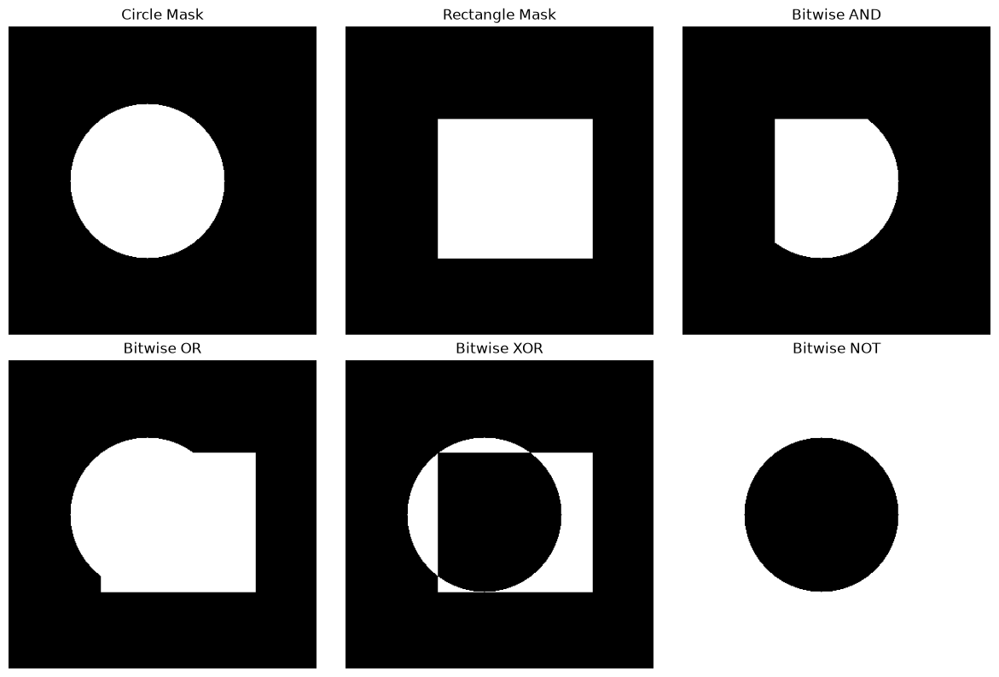

In [18]:
mask1 = np.zeros((400, 400), dtype=np.uint8)
mask2 = np.zeros((400, 400), dtype=np.uint8)

cv2.circle(
    mask1,
    (180, 200),
    100,
    255,
    -1
)

cv2.rectangle(
    mask2,
    (120, 120),
    (320, 300),
    255,
    -1
)

bitwise_and = cv2.bitwise_and(mask1, mask2)

bitwise_or = cv2.bitwise_or(mask1, mask2)

bitwise_xor = cv2.bitwise_xor(mask1, mask2)

bitwise_not = cv2.bitwise_not(mask1)

images = [
    mask1,
    mask2,
    bitwise_and,
    bitwise_or,
    bitwise_xor,
    bitwise_not
]

titles = [
    "Circle Mask",
    "Rectangle Mask",
    "Bitwise AND",
    "Bitwise OR",
    "Bitwise XOR",
    "Bitwise NOT"
]

plt.figure(figsize=(12, 8))

for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

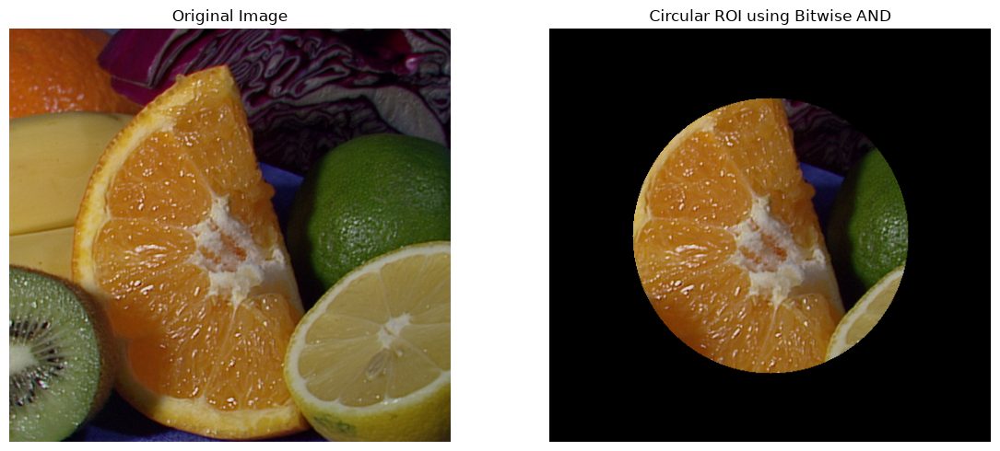

In [19]:
photo = cv2.imread("data/images/fruits.jpg")

height, width = photo.shape[:2]

circle_mask = np.zeros((height, width), dtype=np.uint8)

center = (width // 2, height // 2)
radius = min(width, height) // 3

cv2.circle(circle_mask, center, radius, 255, -1)

circular_roi = cv2.bitwise_and(photo, photo, mask=circle_mask)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(photo, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(circular_roi, cv2.COLOR_BGR2RGB))
plt.title("Circular ROI using Bitwise AND")
plt.axis("off")

plt.tight_layout()
plt.show()

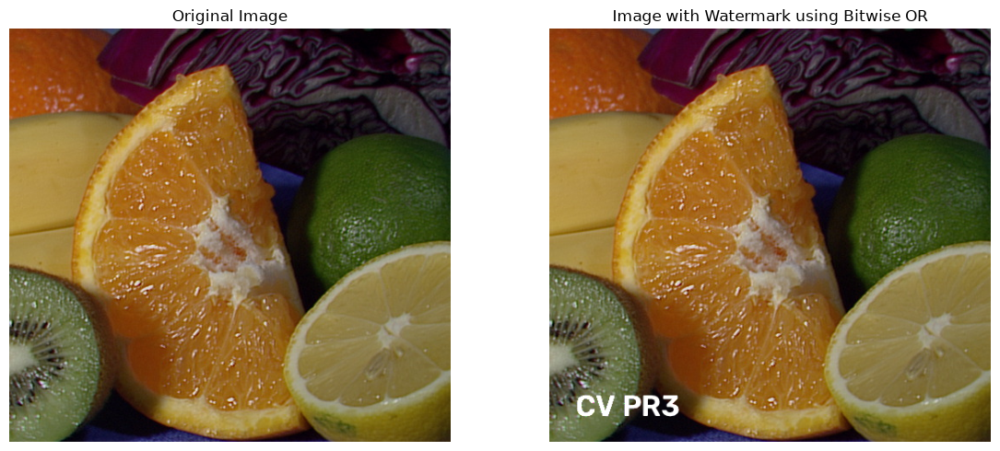

In [20]:
watermark = np.zeros_like(photo)

cv2.putText(
    watermark,
    "CV PR3",
    (30, height - 30),
    cv2.FONT_HERSHEY_SIMPLEX,
    1.2,
    (255, 255, 255),
    3
)

watermarked_image = cv2.bitwise_or(photo, watermark)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(photo, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(watermarked_image, cv2.COLOR_BGR2RGB))
plt.title("Image with Watermark using Bitwise OR")
plt.axis("off")

plt.tight_layout()
plt.show()

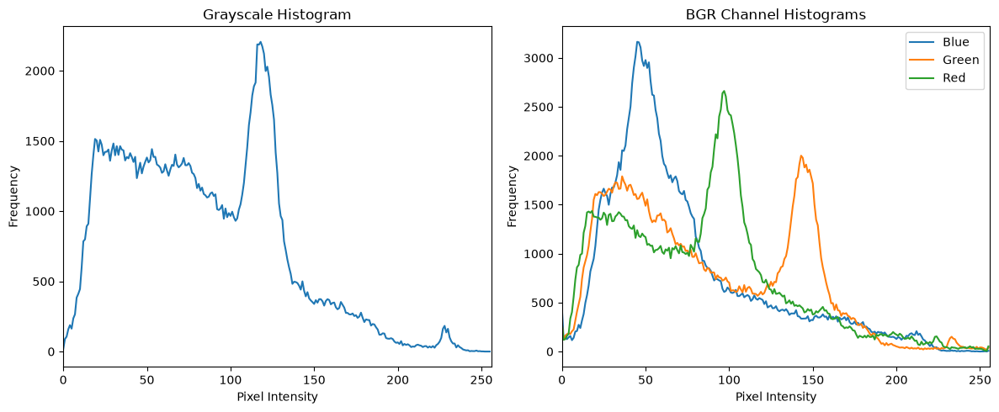

In [21]:
image = cv2.imread("data/images/messi5.jpg")

gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

gray_hist = cv2.calcHist([gray_image], [0], None, [256], [0, 256])

blue_hist = cv2.calcHist([image], [0], None, [256], [0, 256])
green_hist = cv2.calcHist([image], [1], None, [256], [0, 256])
red_hist = cv2.calcHist([image], [2], None, [256], [0, 256])

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(gray_hist)
plt.title("Grayscale Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim([0, 256])

plt.subplot(1, 2, 2)
plt.plot(blue_hist, label="Blue")
plt.plot(green_hist, label="Green")
plt.plot(red_hist, label="Red")
plt.title("BGR Channel Histograms")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim([0, 256])
plt.legend()

plt.tight_layout()
plt.show()

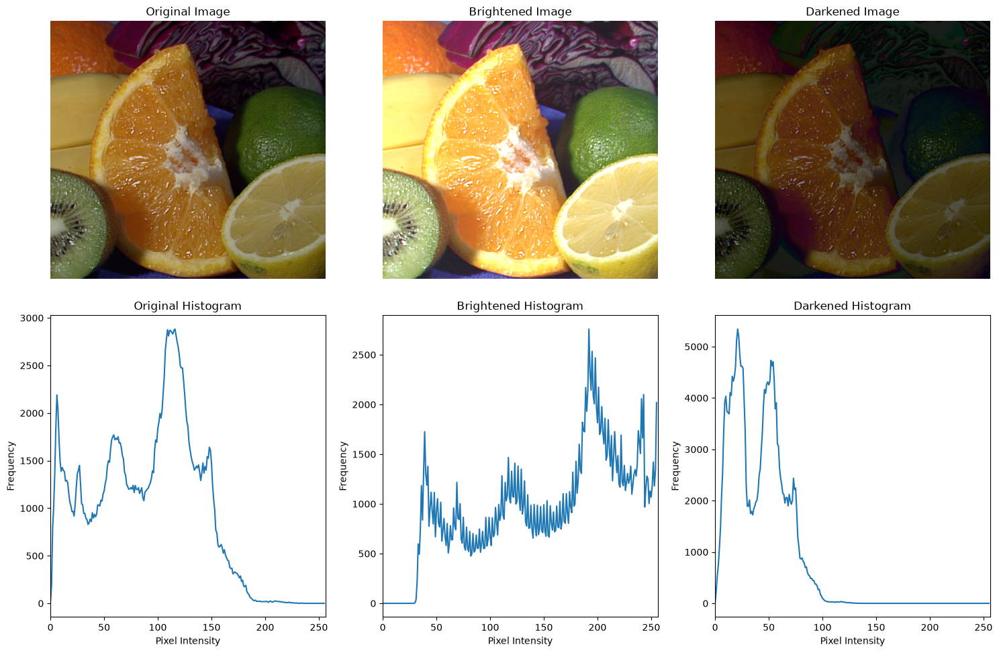

In [22]:
image = cv2.imread("data/images/fruits.jpg")

bright_image = cv2.convertScaleAbs(image, alpha=1.5, beta=30)

dark_image = cv2.convertScaleAbs(image, alpha=0.7, beta=-30)

gray_original = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
gray_bright = cv2.cvtColor(bright_image, cv2.COLOR_BGR2GRAY)
gray_dark = cv2.cvtColor(dark_image, cv2.COLOR_BGR2GRAY)

hist_original = cv2.calcHist([gray_original], [0], None, [256], [0, 256])
hist_bright = cv2.calcHist([gray_bright], [0], None, [256], [0, 256])
hist_dark = cv2.calcHist([gray_dark], [0], None, [256], [0, 256])

plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(cv2.cvtColor(bright_image, cv2.COLOR_BGR2RGB))
plt.title("Brightened Image")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(cv2.cvtColor(dark_image, cv2.COLOR_BGR2RGB))
plt.title("Darkened Image")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.plot(hist_original)
plt.title("Original Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim([0, 256])

plt.subplot(2, 3, 5)
plt.plot(hist_bright)
plt.title("Brightened Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim([0, 256])

plt.subplot(2, 3, 6)
plt.plot(hist_dark)
plt.title("Darkened Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim([0, 256])

plt.tight_layout()
plt.show()

In [26]:
image = cv2.imread("data/images/messi5.jpg")

height, width = image.shape[:2]

model_path = "models/face_detection_yunet_2026may.onnx"

face_detector = cv2.FaceDetectorYN.create(
    model_path,
    "",
    (width, height),
    score_threshold=0.7,
    nms_threshold=0.3,
    top_k=5000
)

face_detector.setInputSize((width, height))

retval, faces = face_detector.detect(image)

print("Faces detected:", 0 if faces is None else len(faces))

Faces detected: 1


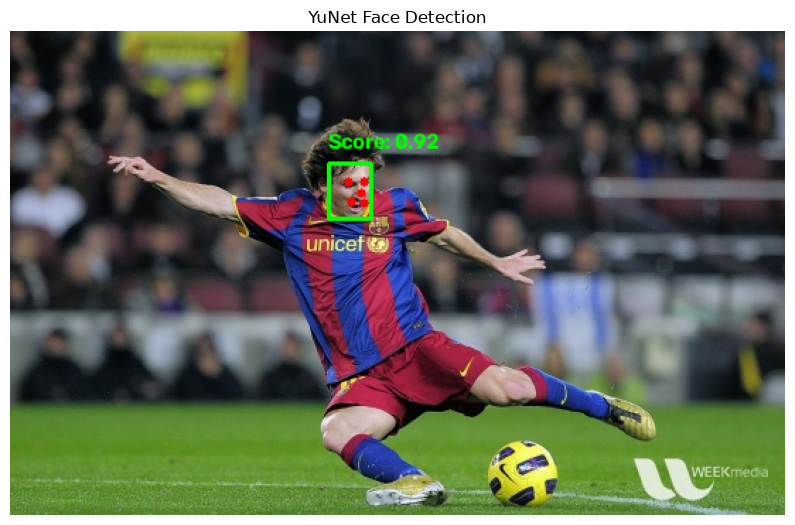

In [27]:
result_image = image.copy()

if faces is not None:
    for face in faces:
        x, y, w, h = face[:4].astype(int)

        cv2.rectangle(
            result_image,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

        landmarks = face[4:14].astype(int).reshape(5, 2)

        for point in landmarks:
            cv2.circle(
                result_image,
                tuple(point),
                3,
                (0, 0, 255),
                -1
            )

        score = face[14]
        cv2.putText(
            result_image,
            f"Score: {score:.2f}",
            (x, max(y - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 255, 0),
            2
        )

plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB))
plt.title("YuNet Face Detection")
plt.axis("off")
plt.show()

C:\Users\rajw1\pr3\data\images\faces\lena.jpg - Faces detected: 1


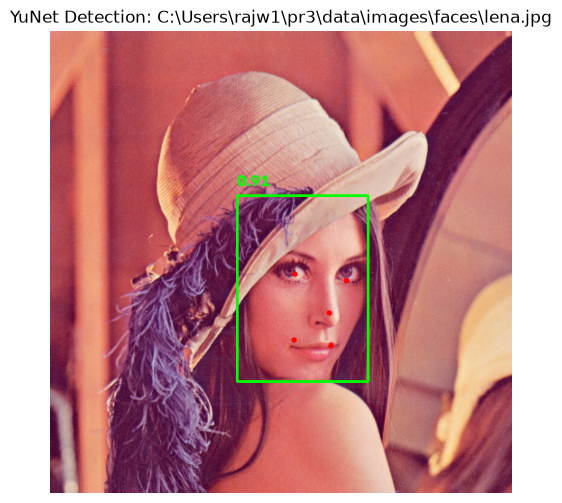

C:\Users\rajw1\pr3\data\images\faces\messi5.jpg - Faces detected: 1


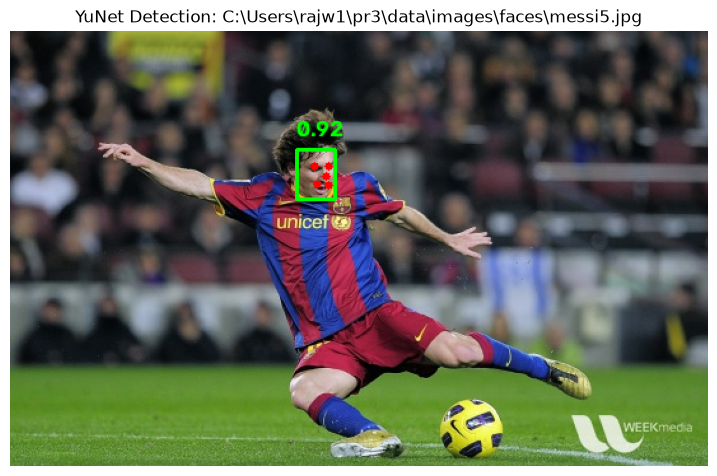

In [29]:
image_paths = [
    "C:\\Users\\rajw1\\pr3\\data\\images\\faces\\lena.jpg",
    "C:\\Users\\rajw1\\pr3\\data\\images\\faces\\messi5.jpg",
]

model_path = "models/face_detection_yunet_2026may.onnx"

for image_path in image_paths:

    image = cv2.imread(image_path)

    if image is None:
        print("Image not found:", image_path)
        continue

    height, width = image.shape[:2]

    detector = cv2.FaceDetectorYN.create(
        model_path,
        "",
        (width, height),
        score_threshold=0.7,
        nms_threshold=0.3,
        top_k=5000
    )

    detector.setInputSize((width, height))

    retval, faces = detector.detect(image)

    result = image.copy()

    face_count = 0 if faces is None else len(faces)

    if faces is not None:
        for face in faces:

            x, y, w, h = face[:4].astype(int)

            cv2.rectangle(
                result,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

            landmarks = face[4:14].astype(int).reshape(5, 2)

            for point in landmarks:
                cv2.circle(
                    result,
                    tuple(point),
                    3,
                    (0, 0, 255),
                    -1
                )

            score = face[14]

            cv2.putText(
                result,
                f"{score:.2f}",
                (x, max(y - 10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (0, 255, 0),
                2
            )

    print(f"{image_path} - Faces detected: {face_count}")

    plt.figure(figsize=(9, 6))
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title(f"YuNet Detection: {image_path}")
    plt.axis("off")
    plt.show()

In [30]:
import cv2
import time

model_path = "models/face_detection_yunet_2026may.onnx"

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("Error: Webcam not accessible.")
else:
    ret, frame = cap.read()

    if ret:
        height, width = frame.shape[:2]

        detector = cv2.FaceDetectorYN.create(
            model_path,
            "",
            (width, height),
            score_threshold=0.7,
            nms_threshold=0.3,
            top_k=5000
        )

        detector.setInputSize((width, height))

        frame_count = 0
        start_time = time.time()
        fps = 0

        while True:
            ret, frame = cap.read()

            if not ret:
                break

            retval, faces = detector.detect(frame)

            if faces is not None:
                for face in faces:
                    x, y, w, h = face[:4].astype(int)

                    cv2.rectangle(
                        frame,
                        (x, y),
                        (x + w, y + h),
                        (0, 255, 0),
                        2
                    )

                    landmarks = face[4:14].astype(int).reshape(5, 2)

                    for point in landmarks:
                        cv2.circle(
                            frame,
                            tuple(point),
                            3,
                            (0, 0, 255),
                            -1
                        )

            frame_count += 1
            elapsed_time = time.time() - start_time

            if elapsed_time >= 1:
                fps = frame_count / elapsed_time
                frame_count = 0
                start_time = time.time()

            cv2.putText(
                frame,
                f"FPS: {fps:.2f}",
                (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX,
                1,
                (255, 0, 0),
                2
            )

            cv2.imshow("YuNet Real-Time Face Detection", frame)

            if cv2.waitKey(1) & 0xFF == ord('q'):
                break

    cap.release()
    cv2.destroyAllWindows()

Threshold 0.5: 1 faces detected
Threshold 0.7: 1 faces detected
Threshold 0.9: 1 faces detected


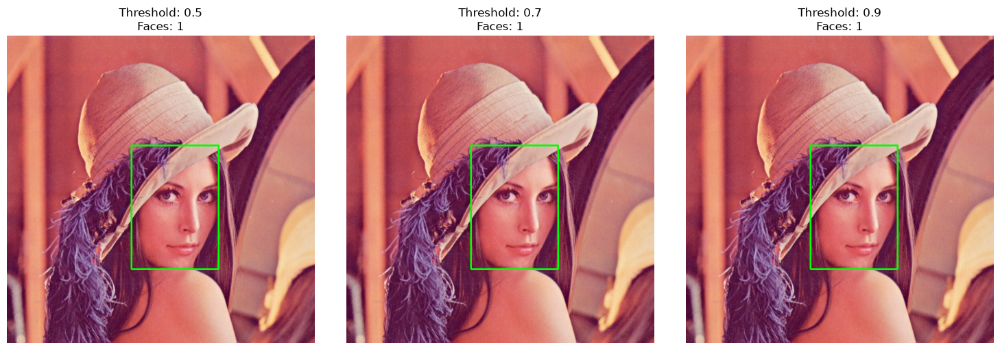

In [31]:
import cv2
import matplotlib.pyplot as plt

image = cv2.imread("C:\\Users\\rajw1\\pr3\\data\\images\\faces\\lena.jpg")

if image is None:
    raise FileNotFoundError("Please check data/images/face1.jpg")

height, width = image.shape[:2]

model_path = "models/face_detection_yunet_2026may.onnx"

thresholds = [0.5, 0.7, 0.9]

plt.figure(figsize=(15, 5))

for i, threshold in enumerate(thresholds):

    detector = cv2.FaceDetectorYN.create(
        model_path,
        "",
        (width, height),
        score_threshold=threshold,
        nms_threshold=0.3,
        top_k=5000
    )

    detector.setInputSize((width, height))

    retval, faces = detector.detect(image)

    result = image.copy()
    face_count = 0 if faces is None else len(faces)

    if faces is not None:
        for face in faces:
            x, y, w, h = face[:4].astype(int)

            cv2.rectangle(
                result,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

    print(f"Threshold {threshold}: {face_count} faces detected")

    plt.subplot(1, 3, i + 1)
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title(f"Threshold: {threshold}\nFaces: {face_count}")
    plt.axis("off")

plt.tight_layout()
plt.show()

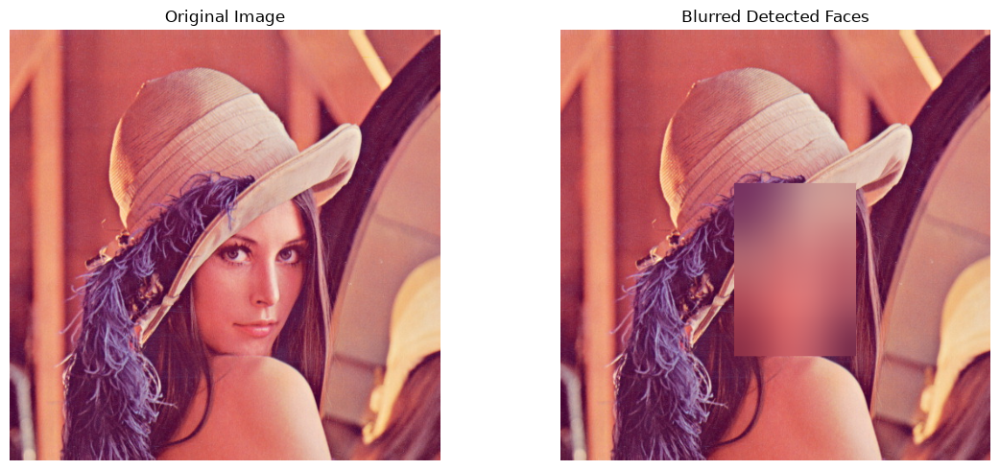

In [32]:
detector = cv2.FaceDetectorYN.create(
    model_path,
    "",
    (width, height),
    score_threshold=0.7,
    nms_threshold=0.3,
    top_k=5000
)

detector.setInputSize((width, height))

retval, faces = detector.detect(image)

blurred_image = image.copy()

if faces is not None:
    for face in faces:

        x, y, w, h = face[:4].astype(int)

        x1 = max(0, x)
        y1 = max(0, y)
        x2 = min(width, x + w)
        y2 = min(height, y + h)

        face_roi = blurred_image[y1:y2, x1:x2]

        if face_roi.size > 0:
            blurred_image[y1:y2, x1:x2] = cv2.GaussianBlur(
                face_roi,
                (99, 99),
                30
            )

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(blurred_image, cv2.COLOR_BGR2RGB))
plt.title("Blurred Detected Faces")
plt.axis("off")

plt.tight_layout()
plt.show()

In [33]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

model = YOLO("yolov8n.pt")

Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\rajw1\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings



image 1/1 c:\Users\rajw1\pr3\data\images\fruits.jpg: 608x640 3 oranges, 207.6ms
Speed: 21.3ms preprocess, 207.6ms inference, 15.5ms postprocess per image at shape (1, 3, 608, 640)

Image: data/images/fruits.jpg
Object: orange, Confidence: 0.83
Object: orange, Confidence: 0.38
Object: orange, Confidence: 0.26


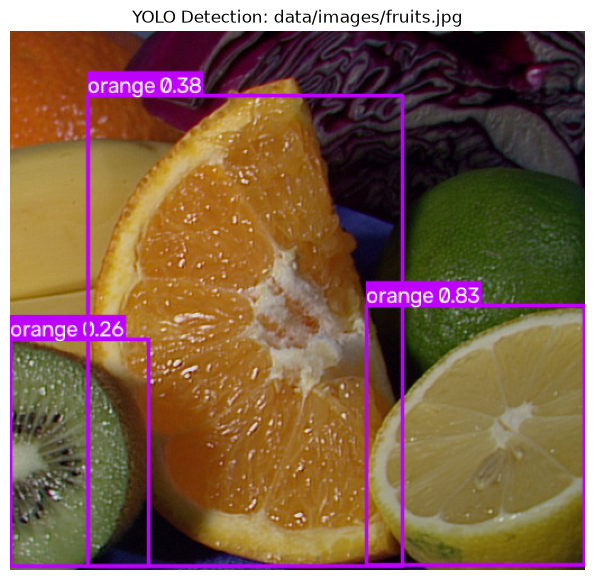


image 1/1 c:\Users\rajw1\pr3\data\images\HappyFish.jpg: 480x640 1 scissors, 221.1ms
Speed: 4.5ms preprocess, 221.1ms inference, 1.8ms postprocess per image at shape (1, 3, 480, 640)

Image: data/images/HappyFish.jpg
Object: scissors, Confidence: 0.33


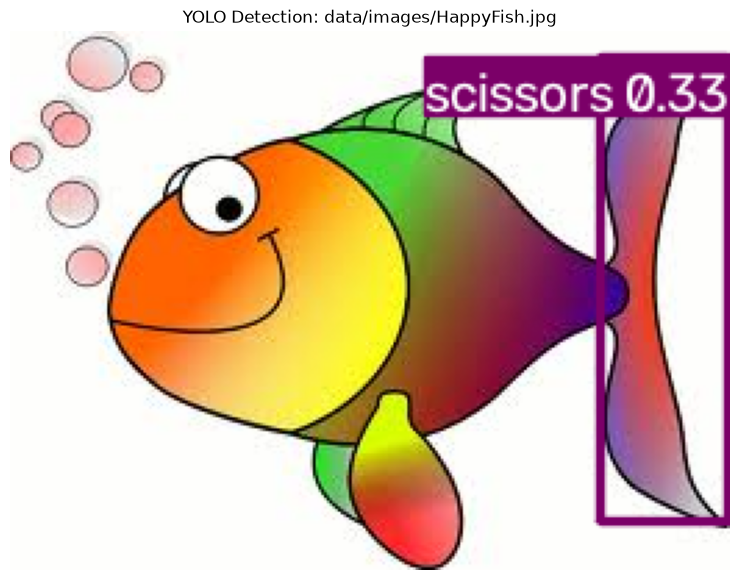


image 1/1 c:\Users\rajw1\pr3\data\images\Blender_Suzanne1.jpg: 480x640 2 umbrellas, 54.6ms
Speed: 2.4ms preprocess, 54.6ms inference, 1.8ms postprocess per image at shape (1, 3, 480, 640)

Image: data/images/Blender_Suzanne1.jpg
Object: umbrella, Confidence: 0.30
Object: umbrella, Confidence: 0.25


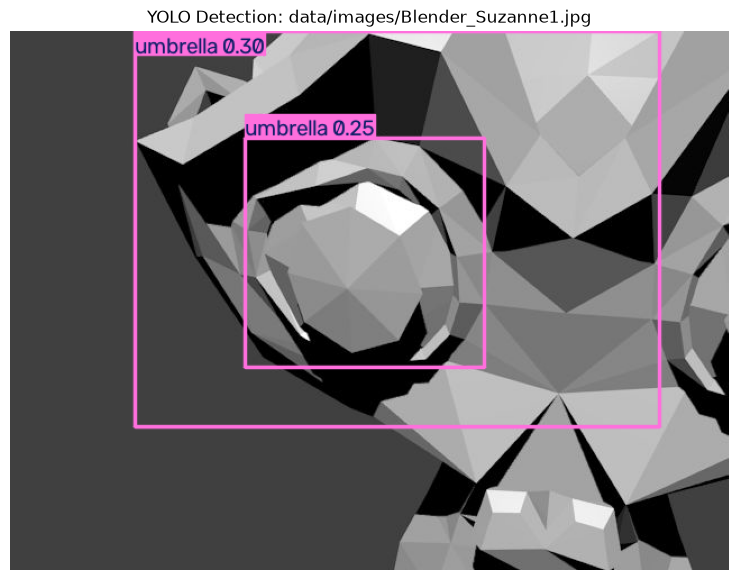

In [34]:
image_paths = [
    "data/images/fruits.jpg",
    "data/images/HappyFish.jpg",
    "data/images/Blender_Suzanne1.jpg"
]

for image_path in image_paths:

    results = model(image_path)

    result_image = results[0].plot()

    boxes = results[0].boxes

    print("\nImage:", image_path)

    if boxes is not None:
        for box in boxes:
            class_id = int(box.cls[0])
            confidence = float(box.conf[0])
            class_name = model.names[class_id]

            print(
                f"Object: {class_name}, "
                f"Confidence: {confidence:.2f}"
            )

    plt.figure(figsize=(10, 7))
    plt.imshow(cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB))
    plt.title(f"YOLO Detection: {image_path}")
    plt.axis("off")
    plt.show()

In [35]:
import cv2
import time
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("Error: Webcam not accessible.")

else:
    frame_count = 0
    start_time = time.time()
    fps = 0

    while True:
        ret, frame = cap.read()

        if not ret:
            break

        results = model(frame, verbose=False)

        result_frame = results[0].plot()

        frame_count += 1
        elapsed_time = time.time() - start_time

        if elapsed_time >= 1:
            fps = frame_count / elapsed_time
            frame_count = 0
            start_time = time.time()

        cv2.putText(
            result_frame,
            f"FPS: {fps:.2f}",
            (20, 40),
            cv2.FONT_HERSHEY_SIMPLEX,
            1,
            (255, 0, 0),
            2
        )

        cv2.imshow("YOLO Real-Time Object Detection", result_frame)

        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

    cap.release()
    cv2.destroyAllWindows()

Confidence: 0.25 | Detections: 3
Confidence: 0.5 | Detections: 1
Confidence: 0.75 | Detections: 1


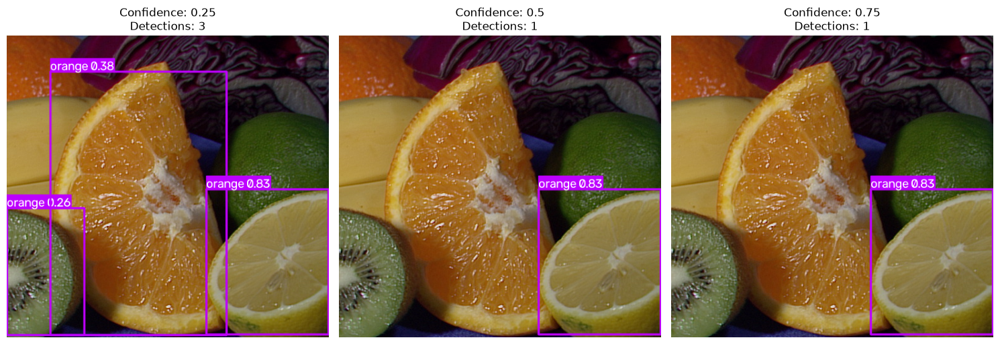

In [36]:
import cv2
import matplotlib.pyplot as plt

image_path = "data/images/fruits.jpg"

confidence_values = [0.25, 0.5, 0.75]

plt.figure(figsize=(15, 5))

for i, conf in enumerate(confidence_values):

    results = model.predict(
        source=image_path,
        conf=conf,
        verbose=False
    )

    result_image = results[0].plot()

    detection_count = len(results[0].boxes)

    print(f"Confidence: {conf} | Detections: {detection_count}")

    plt.subplot(1, 3, i + 1)
    plt.imshow(cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB))
    plt.title(f"Confidence: {conf}\nDetections: {detection_count}")
    plt.axis("off")

plt.tight_layout()
plt.show()

IoU: 0.3 | Detections: 3
IoU: 0.5 | Detections: 3
IoU: 0.7 | Detections: 3


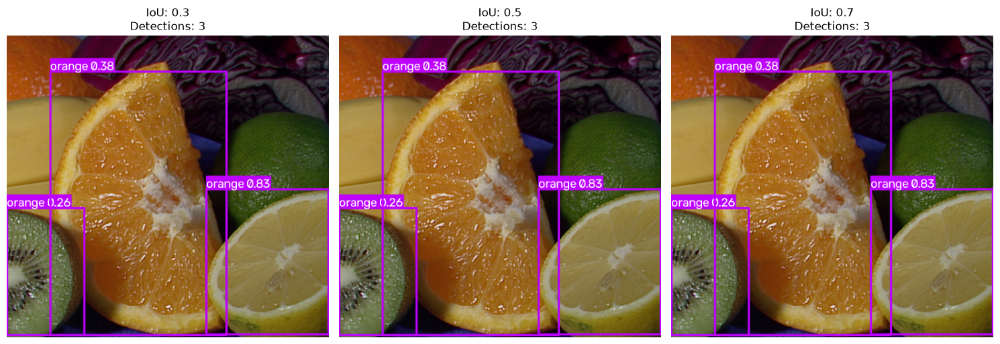

In [37]:
iou_values = [0.3, 0.5, 0.7]

plt.figure(figsize=(15, 5))

for i, iou in enumerate(iou_values):

    results = model.predict(
        source=image_path,
        conf=0.25,
        iou=iou,
        verbose=False
    )

    result_image = results[0].plot()

    detection_count = len(results[0].boxes)

    print(f"IoU: {iou} | Detections: {detection_count}")

    plt.subplot(1, 3, i + 1)
    plt.imshow(cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB))
    plt.title(f"IoU: {iou}\nDetections: {detection_count}")
    plt.axis("off")

plt.tight_layout()
plt.show()

COCO Object Detection Counts:
orange: 3
scissors: 1
umbrella: 2


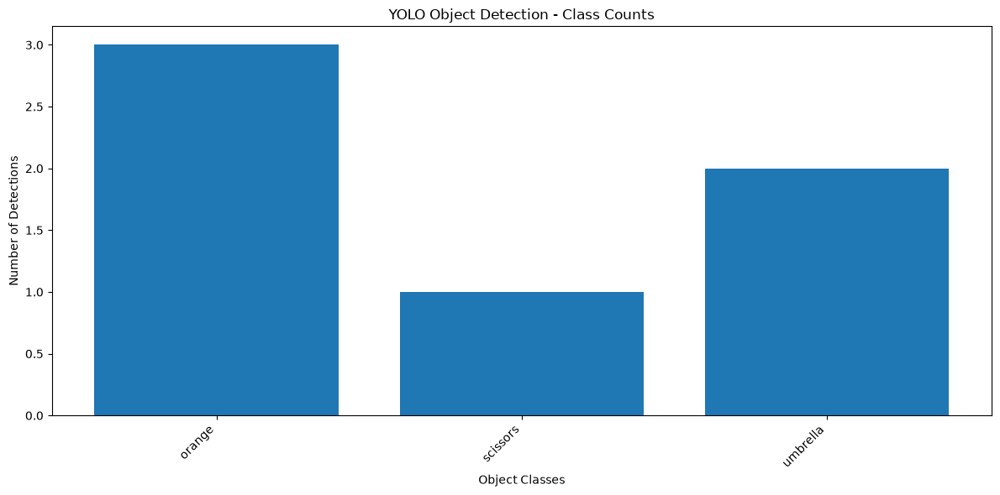

In [38]:
from collections import Counter
import matplotlib.pyplot as plt

image_paths = [
    "data/images/fruits.jpg",
    "data/images/HappyFish.jpg",
    "data/images/Blender_Suzanne1.jpg"
]

class_counts = Counter()

for image_path in image_paths:

    results = model.predict(
        source=image_path,
        conf=0.25,
        verbose=False
    )

    boxes = results[0].boxes

    if boxes is not None:
        for box in boxes:
            class_id = int(box.cls[0])
            class_name = model.names[class_id]

            class_counts[class_name] += 1

print("COCO Object Detection Counts:")

for class_name, count in class_counts.items():
    print(f"{class_name}: {count}")

if class_counts:

    classes = list(class_counts.keys())
    counts = list(class_counts.values())

    plt.figure(figsize=(12, 6))
    plt.bar(classes, counts)

    plt.title("YOLO Object Detection - Class Counts")
    plt.xlabel("Object Classes")
    plt.ylabel("Number of Detections")
    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()
    plt.show()

else:
    print("No objects detected in the selected images.")

In [39]:
import cv2
import time
from ultralytics import YOLO

yolo_model = YOLO("yolov8n.pt")

yunet_path = "models/face_detection_yunet_2026may.onnx"

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("Error: Webcam not accessible.")

else:
    ret, frame = cap.read()

    if ret:
        height, width = frame.shape[:2]

        face_detector = cv2.FaceDetectorYN.create(
            yunet_path,
            "",
            (width, height),
            score_threshold=0.7,
            nms_threshold=0.3,
            top_k=5000
        )

        face_detector.setInputSize((width, height))

        while True:
            ret, frame = cap.read()

            if not ret:
                break

          
            retval, faces = face_detector.detect(frame)

            if faces is not None:
                for face in faces:
                    x, y, w, h = face[:4].astype(int)

                    cv2.rectangle(
                        frame,
                        (x, y),
                        (x + w, y + h),
                        (0, 255, 0),
                        2
                    )

                    cv2.putText(
                        frame,
                        "Face",
                        (x, max(y - 10, 20)),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.6,
                        (0, 255, 0),
                        2
                    )

            results = yolo_model(frame, conf=0.25, verbose=False)

            for box in results[0].boxes:
                x1, y1, x2, y2 = box.xyxy[0].int().tolist()

                class_id = int(box.cls[0])
                class_name = yolo_model.names[class_id]
                confidence = float(box.conf[0])

                cv2.rectangle(
                    frame,
                    (x1, y1),
                    (x2, y2),
                    (0, 0, 255),
                    2
                )

                cv2.putText(
                    frame,
                    f"{class_name} {confidence:.2f}",
                    (x1, max(y1 - 10, 20)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.6,
                    (0, 0, 255),
                    2
                )

            cv2.imshow(
                "YuNet + YOLO Combined Detection",
                frame
            )

            if cv2.waitKey(1) & 0xFF == ord('q'):
                break

    cap.release()
    cv2.destroyAllWindows()

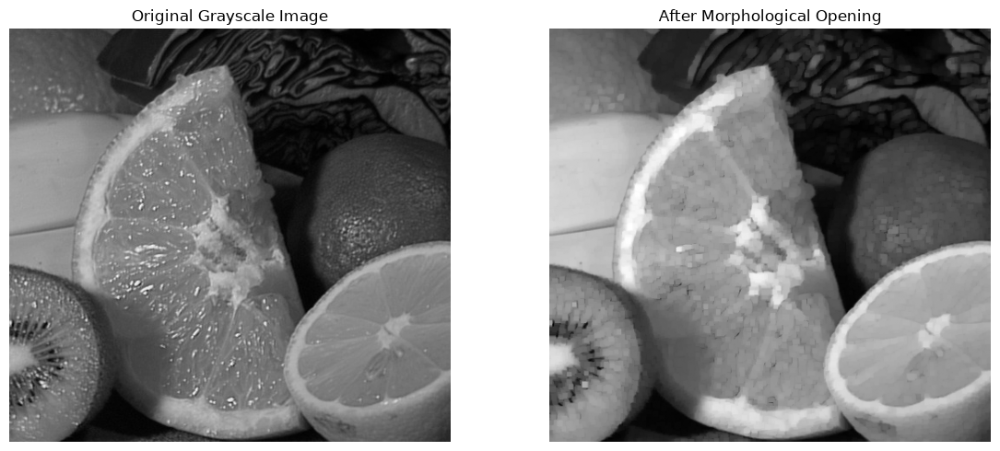

In [40]:
import cv2
import matplotlib.pyplot as plt

image = cv2.imread("data/images/fruits.jpg")

gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    (5, 5)
)

opened_image = cv2.morphologyEx(
    gray_image,
    cv2.MORPH_OPEN,
    kernel
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(opened_image, cmap="gray")
plt.title("After Morphological Opening")
plt.axis("off")

plt.tight_layout()
plt.show()

Original Image Detections: 3
Denoised Image Detections: 1


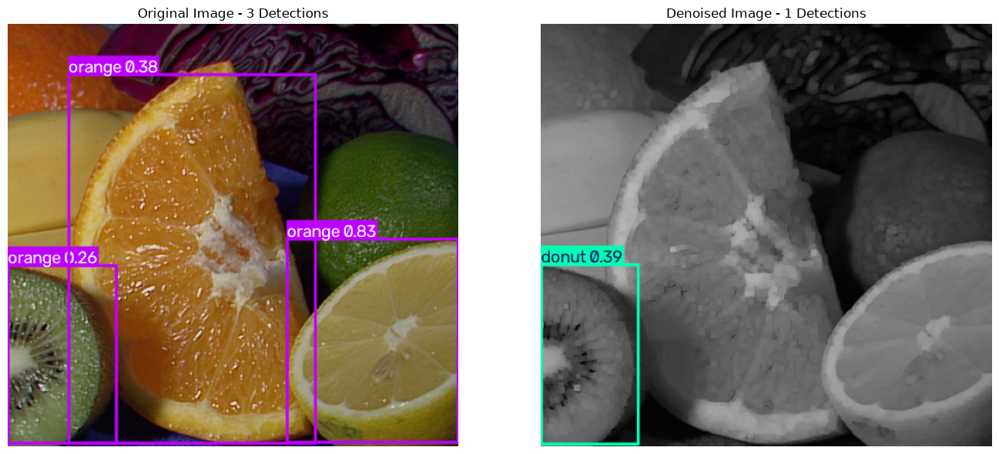

In [41]:
denoised_color = cv2.cvtColor(
    opened_image,
    cv2.COLOR_GRAY2BGR
)

original_results = yolo_model.predict(
    source=image,
    conf=0.25,
    verbose=False
)

denoised_results = yolo_model.predict(
    source=denoised_color,
    conf=0.25,
    verbose=False
)

original_count = len(original_results[0].boxes)
denoised_count = len(denoised_results[0].boxes)

print("Original Image Detections:", original_count)
print("Denoised Image Detections:", denoised_count)

original_output = original_results[0].plot()
denoised_output = denoised_results[0].plot()

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(original_output, cv2.COLOR_BGR2RGB))
plt.title(f"Original Image - {original_count} Detections")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(denoised_output, cv2.COLOR_BGR2RGB))
plt.title(f"Denoised Image - {denoised_count} Detections")
plt.axis("off")

plt.tight_layout()
plt.show()

FPS Comparison:


,Technique,FPS
0,YuNet,25.556825
1,YOLO,22.701960
2,Combined,14.054097


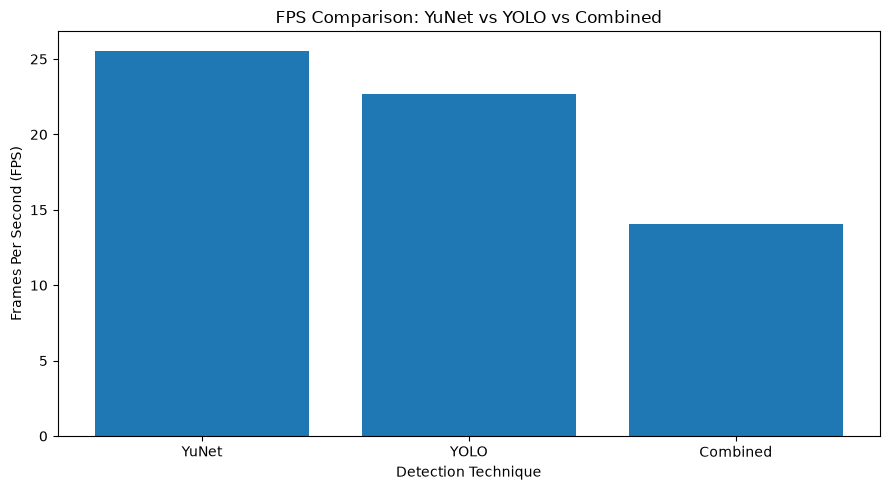

In [42]:
import cv2
import time
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

yolo_model = YOLO("yolov8n.pt")

yunet_path = "models/face_detection_yunet_2026may.onnx"

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    raise RuntimeError("Webcam not accessible.")

ret, frame = cap.read()

if not ret:
    cap.release()
    raise RuntimeError("Unable to read webcam frame.")

height, width = frame.shape[:2]

face_detector = cv2.FaceDetectorYN.create(
    yunet_path,
    "",
    (width, height),
    score_threshold=0.7,
    nms_threshold=0.3,
    top_k=5000
)

face_detector.setInputSize((width, height))

fps_results = {}

frame_limit = 100


frames = []
for _ in range(frame_limit):
    ret, frame = cap.read()
    if not ret:
        break
    frames.append(frame)

if len(frames) != frame_limit:
    cap.release()
    raise RuntimeError("Could not capture 100 frames.")

start_time = time.time()

for frame in frames:
    face_detector.detect(frame)

yunet_time = time.time() - start_time
fps_results["YuNet"] = frame_limit / yunet_time


start_time = time.time()

for frame in frames:
    yolo_model.predict(frame, verbose=False)

yolo_time = time.time() - start_time
fps_results["YOLO"] = frame_limit / yolo_time


start_time = time.time()

for frame in frames:
    face_detector.detect(frame)
    yolo_model.predict(frame, verbose=False)

combined_time = time.time() - start_time
fps_results["Combined"] = frame_limit / combined_time

cap.release()


fps_df = pd.DataFrame({
    "Technique": list(fps_results.keys()),
    "FPS": list(fps_results.values())
})

print("FPS Comparison:")
display(fps_df)

plt.figure(figsize=(9, 5))

plt.bar(
    fps_df["Technique"],
    fps_df["FPS"]
)

plt.title("FPS Comparison: YuNet vs YOLO vs Combined")
plt.xlabel("Detection Technique")
plt.ylabel("Frames Per Second (FPS)")

plt.tight_layout()
plt.show()

In [43]:
import pandas as pd

comparison_data = {
    "Technique": [
        "YuNet",
        "YOLO",
        "Combined (YuNet + YOLO)"
    ],

    "Type": [
        "Face Detection",
        "Object Detection",
        "Face + Object Detection"
    ],

    "What Detects": [
        "Human Faces",
        "Multiple COCO Objects",
        "Human Faces and COCO Objects"
    ],

    "Lighting Robustness": [
        "Depends on lighting and face visibility",
        "Depends on lighting and object visibility",
        "Depends on both models and image quality"
    ],

    "FPS": [
        round(fps_results["YuNet"], 2),
        round(fps_results["YOLO"], 2),
        round(fps_results["Combined"], 2)
    ],

    "Best Use Case": [
        "Face Detection and Attendance",
        "Real-Time Object Detection",
        "Integrated Computer Vision Systems"
    ]
}

comparison_df = pd.DataFrame(comparison_data)

display(comparison_df)

,Technique,Type,What Detects,Lighting Robustness,FPS,Best Use Case
0,YuNet,Face Detection,Human Faces,Depends on lighting and face visibility,25.56,Face Detection and Attendance
1,YOLO,Object Detection,Multiple COCO Objects,Depends on lighting and object visibility,22.70,Real-Time Object Detection
2,Combined (YuNet + YOLO),Face + Object Detection,Human Faces and COCO Objects,Depends on both models and image quality,14.05,Integrated Computer Vision Systems
